In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [55]:
df = pd.read_csv('Zomato-data-.csv')


In [56]:
print("First 5 Records:")
print(df.head())

First 5 Records:
                    name online_order book_table   rate  votes  \
0                  Jalsa          Yes        Yes  4.1/5    775   
1         Spice Elephant          Yes         No  4.1/5    787   
2        San Churro Cafe          Yes         No  3.8/5    918   
3  Addhuri Udupi Bhojana           No         No  3.7/5     88   
4          Grand Village           No         No  3.8/5    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [57]:
print("\nDataset Information:")
print(df.info())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   name                         148 non-null    str  
 1   online_order                 148 non-null    str  
 2   book_table                   148 non-null    str  
 3   rate                         148 non-null    str  
 4   votes                        148 non-null    int64
 5   approx_cost(for two people)  148 non-null    int64
 6   listed_in(type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 8.2 KB
None


In [58]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(148, 7)


In [59]:
print("\nColumn Names:")
print(df.columns)



Column Names:
Index(['name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='str')


In [60]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
             votes  approx_cost(for two people)
count   148.000000                   148.000000
mean    264.810811                   418.243243
std     653.676951                   223.085098
min       0.000000                   100.000000
25%       6.750000                   200.000000
50%      43.500000                   400.000000
75%     221.750000                   600.000000
max    4884.000000                   950.000000


In [61]:
print("\nData Types:")
print(df.dtypes)


Data Types:
name                             str
online_order                     str
book_table                       str
rate                             str
votes                          int64
approx_cost(for two people)    int64
listed_in(type)                  str
dtype: object


In [62]:
print("\nDuplicate Records:")
print(df.duplicated().sum())


Duplicate Records:
0


In [63]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64


In [64]:
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())



Total Missing Values:
0


In [65]:
df['rate'] = (
    df['rate']
    .astype(str)
    .str.extract(r'(\d+\.?\d*)')[0]
    .astype(float)
)

In [66]:
print("\nConverted Ratings:")
print(df['rate'].head())


Converted Ratings:
0    4.1
1    4.1
2    3.8
3    3.7
4    3.8
Name: rate, dtype: float64


In [67]:
print("\nMissing Ratings:")
print(df['rate'].isnull().sum())



Missing Ratings:
0


In [69]:
df['Rating_Category'] = df['rate'].apply(
    lambda x: 'Excellent' if x >= 4.0
    else 'Good' if x >= 3.0
    else 'Average'
)

In [70]:
print("\nTransformed Dataset:")
print(df.head())


Transformed Dataset:
                    name online_order book_table  rate  votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   approx_cost(for two people) listed_in(type) Rating_Category  
0                          800          Buffet       Excellent  
1                          800          Buffet       Excellent  
2                          800          Buffet            Good  
3                          300          Buffet            Good  
4                          600          Buffet            Good  


In [71]:
print("\nUpdated Data Types:")
print(df.dtypes)


Updated Data Types:
name                               str
online_order                       str
book_table                         str
rate                           float64
votes                            int64
approx_cost(for two people)      int64
listed_in(type)                    str
Rating_Category                    str
dtype: object


In [72]:
df['rate'] = pd.to_numeric(
    df['rate'].astype(str)
    .str.replace('/5', '', regex=False)
    .str.strip(),
    errors='coerce'
)

In [73]:
print("\nMissing Values Before Imputation:")
print(df.isnull().sum())


Missing Values Before Imputation:
name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
Rating_Category                0
dtype: int64


In [74]:
mean_values = df.select_dtypes(include='number').mean()

In [75]:
print("\nMean Values:")
print(mean_values)


Mean Values:
rate                             3.633108
votes                          264.810811
approx_cost(for two people)    418.243243
dtype: float64


In [76]:
df.fillna(mean_values, inplace=True)

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type),Rating_Category
0,Jalsa,Yes,Yes,4.1,775,800,Buffet,Excellent
1,Spice Elephant,Yes,No,4.1,787,800,Buffet,Excellent
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet,Good
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet,Good
4,Grand Village,No,No,3.8,166,600,Buffet,Good
...,...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3,0,100,Dining,Good
144,New Indraprasta,No,No,3.3,0,150,Dining,Good
145,Anna Kuteera,Yes,No,4.0,771,450,Dining,Excellent
146,Darbar,No,No,3.0,98,800,Dining,Good


In [77]:
print("\nMissing Values After Imputation:")
print(df.isnull().sum())



Missing Values After Imputation:
name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
Rating_Category                0
dtype: int64


In [78]:
print("\nAverage Rating:")
print(df['rate'].mean())


Average Rating:
3.6331081081081082


In [79]:
print("\nMost Voted Restaurant:")
print(df.loc[df['votes'].idxmax(), 'name'])


Most Voted Restaurant:
Empire Restaurant


In [80]:
print("\nAverage Cost:")
print(df['approx_cost(for two people)'].mean())


Average Cost:
418.2432432432432


In [81]:
print("\nOnline Orders:")
print(df['online_order'].value_counts())


Online Orders:
online_order
No     90
Yes    58
Name: count, dtype: int64


In [82]:
print("\nPopular Restaurant Types:")
print(df['listed_in(type)'].value_counts().head(5))


Popular Restaurant Types:
listed_in(type)
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64


Rating Distribution – Histogram

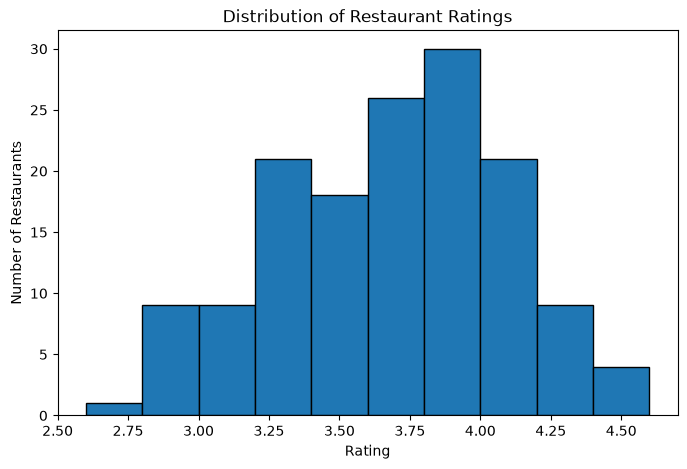

In [83]:
plt.figure(figsize=(8, 5))
plt.hist(df['rate'].dropna(), bins=10, edgecolor='black')
plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')
plt.show()

Online Orders – Bar Chart

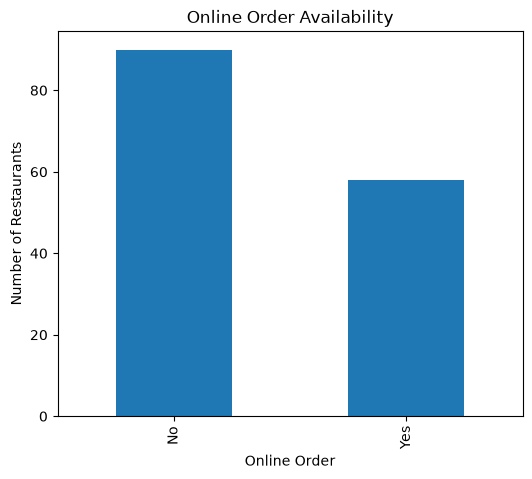

In [84]:
plt.figure(figsize=(6, 5))
df['online_order'].value_counts().plot(kind='bar')
plt.title('Online Order Availability')
plt.xlabel('Online Order')
plt.ylabel('Number of Restaurants')
plt.show()

Restaurant Types – Bar Chart

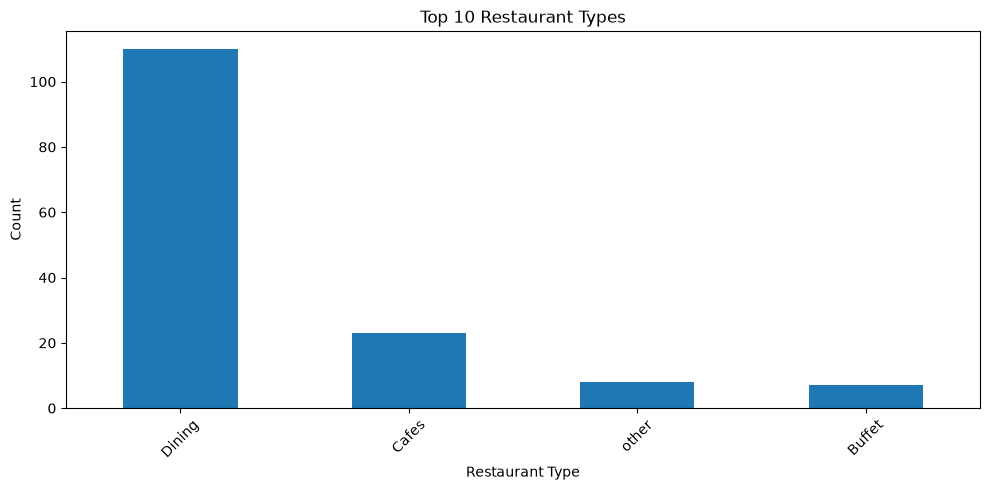

In [85]:
plt.figure(figsize=(10, 5))
df['listed_in(type)'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Restaurant Types')
plt.xlabel('Restaurant Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Rating vs Votes – Scatter Plot

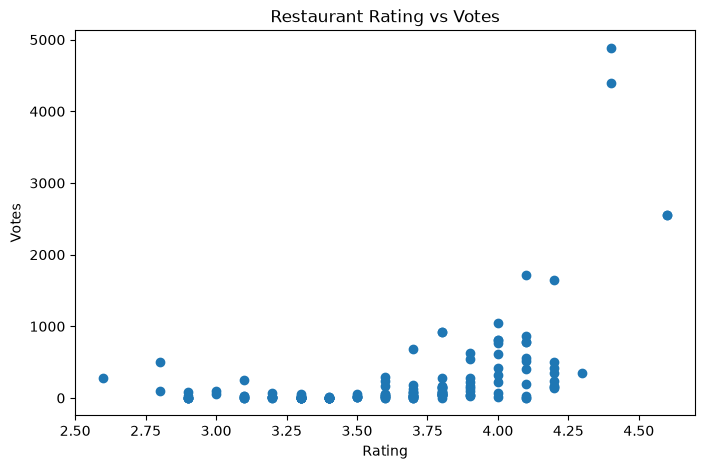

In [86]:
plt.figure(figsize=(8, 5))
plt.scatter(df['rate'], df['votes'])
plt.title('Restaurant Rating vs Votes')
plt.xlabel('Rating')
plt.ylabel('Votes')
plt.show()

In [87]:
df.to_csv("cleaned_zomato_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
